# Evaluación 3: Modelado predictivo de riesgo crediticio con `DecisionTreeClassifier`

**Autores:**
- Cristóbal Soto Vidal - cristobal.soto2301@alumnos.ubiobio.cl
- Martín Romero Álvarez - martin.romero2301@alumnos.ubiobio.cl
- Benjamín Paredes Aguayo - benjamin.paredes2301@alumnos.ubiobio.cl
- Darío Silva Pedreros - dario.silva2301@alumnos.ubiobio.cl

**Asignatura:** Inteligencia Artificial (620454)  
**Fecha:** Noviembre 2026  
**Versión:** 1.0

---

## Descripción

Una institución financiera recibe solicitudes de **préstamos hipotecarios** y necesita estimar el riesgo de incumplimiento (`Riesgo_Impago`: 1 = impago, 0 = cumple). En este notebook se construye un modelo de clasificación con `DecisionTreeClassifier` y se evalúa con criterios de negocio:

- Aprobar a quien termina en impago (**falso negativo**) cuesta **\$1.500.000** por crédito.
- Rechazar a un cliente que habría pagado (**falso positivo**) cuesta **\$200.000** en intereses no percibidos.

**Objetivo:** comparar un modelo de línea base (árbol por defecto) con un modelo optimizado mediante `GridSearchCV` (5 hiperparámetros) y traducir sus errores a costo financiero.

**Fases:** (1) diagnóstico y calidad de datos · (2) pipeline de limpieza · (3) construcción de los modelos · (4) métricas e interpretación de la matriz de confusión.

---

## Requisitos de Software

Desarrollado con Python 3.12. Bibliotecas necesarias:

- pandas (>=2.1.0)
- numpy
- matplotlib
- seaborn
- scikit-learn (>=1.4)

Todas las operaciones aleatorias usan `random_state = 29`, como indica la pauta.

## Importación de bibliotecas

Todas las importaciones se concentran en esta única celda.

In [1]:
import os
import urllib.request
from urllib.parse import quote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## Constantes del proyecto

Se fijan una sola vez la semilla (`RANDOM_STATE = 29`), el tamaño del conjunto de prueba y los costos del enunciado. Con `TEST_SIZE = 0.4` el conjunto de 25.000 filas queda en 15.000 para entrenamiento y 10.000 para prueba, que se ajusta a la referencia de tamaños dada en clase (10.000 a 15.000 para entrenar y 10.000 para probar).

In [2]:
RANDOM_STATE = 29          # obligatorio en toda la evaluación
TEST_SIZE = 0.4            # 25.000 filas -> 15.000 entrenamiento / 10.000 prueba
COSTO_FN = 1_500_000       # impago aprobado (falso negativo)
COSTO_FP = 200_000         # cliente viable rechazado (falso positivo)
NOMBRES_CLASES = ["Cumple", "Impago"]   # 0 = Cumple, 1 = Impago

## Fuente de datos

El notebook **descarga el archivo por sí mismo** desde el repositorio del grupo en GitHub (la URL se construye con `quote()` para manejar la tilde de `E3-Clasificación`). Si la descarga falla, busca una copia local y, si tampoco existe, se detiene con un mensaje claro.

In [3]:
USUARIO = "BenjiParedes"
REPO = "Ev.1_IA"
RAMA = "main"
CARPETA = "E3-Clasificación"
ARCHIVO = "riesgo_crediticio.csv"

URL_DATOS = f"https://raw.githubusercontent.com/{USUARIO}/{REPO}/{RAMA}/{quote(CARPETA)}/{quote(ARCHIVO)}"
RUTA_DATOS = ARCHIVO

# 1) Descarga desde el repositorio del grupo en GitHub
try:
    urllib.request.urlretrieve(URL_DATOS, RUTA_DATOS)
    print("Dataset descargado desde GitHub.")
except Exception as error:
    print(f"No fue posible descargar desde GitHub ({type(error).__name__}); se intentará usar una copia local.")
    # 2) Respaldo: copia local en ubicaciones habituales
    candidatas = [RUTA_DATOS, os.path.join(CARPETA, RUTA_DATOS), os.path.join("..", RUTA_DATOS)]
    RUTA_DATOS = next((ruta for ruta in candidatas if os.path.exists(ruta)), None)

assert RUTA_DATOS is not None and os.path.exists(RUTA_DATOS), (
    f"No se encontró {ARCHIVO}: verifique la conexión a internet o ubique el archivo junto al notebook."
)

data = pd.read_csv(RUTA_DATOS)
print(f"Dataset cargado: {data.shape[0]} filas x {data.shape[1]} columnas.")
data.head()

Dataset descargado desde GitHub.
Dataset cargado: 25000 filas x 6 columnas.


,Unnamed: 0,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso,Riesgo_Impago
0,0,39785.55,85246.38,694.0,70.00,0
1,1,69773.95,244260.00,622.0,10.65,0
2,2,127770.68,209310.35,780.0,42.70,0
3,3,16799.80,213059.98,741.0,48.04,0
4,4,70229.83,219523.13,714.0,25.58,0


# Fase 1: Diagnóstico y calidad de datos (EDA)

Se revisan estructura, tipos, nulos, duplicados, reglas lógicas de negocio, valores atípicos y el desbalance de la variable objetivo. Los diagnósticos se hacen sobre todo el conjunto y son **solo descriptivos**: ninguna decisión de transformación usa estadísticas globales.

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              25000 non-null  int64  
 1   Ingreso_Anual           25000 non-null  float64
 2   Monto_Prestamo          25000 non-null  float64
 3   Puntaje_Credito         25000 non-null  float64
 4   Relacion_Deuda_Ingreso  25000 non-null  float64
 5   Riesgo_Impago           25000 non-null  int64  
dtypes: float64(4), int64(2)
memory usage: 1.1 MB


**Hallazgo y decisión.** El archivo trae una columna `Unnamed: 0` de 25.000 filas que, como confirma la comprobación, es solo el índice de fila que pandas exportó al CSV. No describe al cliente, por lo que **se elimina** para que el modelo no use una numeración arbitraria como si fuera información. Quedan cuatro variables predictoras y el objetivo.

In [5]:
# La columna "Unnamed: 0" es el índice que pandas exportó al CSV: ¿coincide con la posición de la fila?
print("¿'Unnamed: 0' es solo el índice de fila?:", bool((data["Unnamed: 0"] == np.arange(len(data))).all()))

# No es una característica del cliente: se elimina para que el modelo no la use
data = data.drop(columns=["Unnamed: 0"])
print("Columnas restantes:", list(data.columns))

¿'Unnamed: 0' es solo el índice de fila?: True
Columnas restantes: ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso', 'Riesgo_Impago']


In [6]:
calidad = pd.DataFrame({
    "tipo": data.dtypes.astype(str),
    "nulos": data.isna().sum(),
    "% nulos": (data.isna().mean() * 100).round(2),
    "valores únicos": data.nunique(),
})
print(calidad)
print("\nFilas duplicadas:", int(data.duplicated().sum()))

                           tipo  nulos  % nulos  valores únicos
Ingreso_Anual           float64      0      0.0           24970
Monto_Prestamo          float64      0      0.0           24927
Puntaje_Credito         float64      0      0.0             373
Relacion_Deuda_Ingreso  float64      0      0.0            5109
Riesgo_Impago             int64      0      0.0               2

Filas duplicadas: 0


**Interpretación.** No hay valores nulos en ninguna columna (0 % en todas) ni filas duplicadas. Las cuatro variables predictoras son numéricas continuas (`float64`) y el objetivo es binario (2 valores únicos). Para el negocio esto significa que la información de cada solicitud está completa y que no hay solicitudes repetidas que sesguen el entrenamiento. Se comprobó y **no se encontraron** problemas de nulos ni duplicados, por lo que no se inventan imputaciones.

In [7]:
# Reglas de negocio / inconsistencias lógicas
reglas = {
    "Ingreso_Anual <= 0": int((data["Ingreso_Anual"] <= 0).sum()),
    "Monto_Prestamo <= 0": int((data["Monto_Prestamo"] <= 0).sum()),
    "Puntaje_Credito fuera de 300-850": int((~data["Puntaje_Credito"].between(300, 850)).sum()),
    "Relacion_Deuda_Ingreso fuera de 0-100": int((~data["Relacion_Deuda_Ingreso"].between(0, 100)).sum()),
    "Riesgo_Impago distinto de 0/1": int((~data["Riesgo_Impago"].isin([0, 1])).sum()),
}
pd.Series(reglas, name="registros que violan la regla")

,registros que violan la regla
Ingreso_Anual <= 0,0
Monto_Prestamo <= 0,0
Puntaje_Credito fuera de 300-850,0
Relacion_Deuda_Ingreso fuera de 0-100,0
Riesgo_Impago distinto de 0/1,0


**Interpretación.** Se revisaron las reglas lógicas del negocio: ningún registro tiene ingreso o monto menores o iguales a cero, ningún puntaje queda fuera de la escala 300-850, ningún DTI sale del rango 0-100 y el objetivo solo toma los valores 0 y 1. Los 25.000 registros son coherentes con las definiciones del enunciado. El resumen estadístico muestra además rangos plausibles (por ejemplo, puntajes entre 457 y 850).

In [8]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Ingreso_Anual,25000.0,55824.44,29804.90,7832.12,35051.32,49234.68,68923.52,348135.55
Monto_Prestamo,25000.0,220162.89,60059.30,50000.00,179438.08,220241.47,261003.36,451784.21
Puntaje_Credito,25000.0,680.03,59.78,457.00,640.00,680.00,721.00,850.00
Relacion_Deuda_Ingreso,25000.0,24.03,13.62,5.00,13.79,21.45,31.38,70.00
Riesgo_Impago,25000.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00


In [9]:
# Valores pegados a los extremos de las escalas (posible acotamiento en el origen de los datos)
extremos = {
    "Relacion_Deuda_Ingreso == mínimo": int((data["Relacion_Deuda_Ingreso"] == data["Relacion_Deuda_Ingreso"].min()).sum()),
    "Relacion_Deuda_Ingreso == máximo": int((data["Relacion_Deuda_Ingreso"] == data["Relacion_Deuda_Ingreso"].max()).sum()),
    "Monto_Prestamo == mínimo": int((data["Monto_Prestamo"] == data["Monto_Prestamo"].min()).sum()),
    "Puntaje_Credito == máximo": int((data["Puntaje_Credito"] == data["Puntaje_Credito"].max()).sum()),
}
print("Mínimo y máximo de Relacion_Deuda_Ingreso:", data["Relacion_Deuda_Ingreso"].min(), data["Relacion_Deuda_Ingreso"].max())
print("Mínimo de Monto_Prestamo:", data["Monto_Prestamo"].min(), "| Máximo de Puntaje_Credito:", data["Puntaje_Credito"].max())
pd.Series(extremos, name="registros en el límite")

Mínimo y máximo de Relacion_Deuda_Ingreso: 5.0 70.0
Mínimo de Monto_Prestamo: 50000.0 | Máximo de Puntaje_Credito: 850.0


,registros en el límite
Relacion_Deuda_Ingreso == mínimo,631
Relacion_Deuda_Ingreso == máximo,196
Monto_Prestamo == mínimo,53
Puntaje_Credito == máximo,49


**Hallazgo.** Varias variables se acumulan exactamente en los extremos de su escala: 631 solicitantes tienen el DTI mínimo (5,0) y 196 el máximo (70,0); 53 piden exactamente el monto mínimo (\$50.000) y 49 tienen el puntaje máximo (850). Esto sugiere que los datos fueron **acotados en su origen**. No son errores de captura, pero conviene saberlo: parte de los atípicos del DTI están "topados" en 70 y el modelo no puede distinguir entre un DTI real de 70 y uno mayor.

                        limite_inferior  limite_superior  n_atipicos  \
Ingreso_Anual                 -15756.99        119731.82       976.0   
Monto_Prestamo                 57090.15        383351.29       157.0   
Puntaje_Credito                  518.50           842.50       167.0   
Relacion_Deuda_Ingreso           -12.60            57.77       663.0   

                        % atípicos  asimetria  
Ingreso_Anual                 3.90       1.70  
Monto_Prestamo                0.63      -0.00  
Puntaje_Credito               0.67      -0.03  
Relacion_Deuda_Ingreso        2.65       0.99  


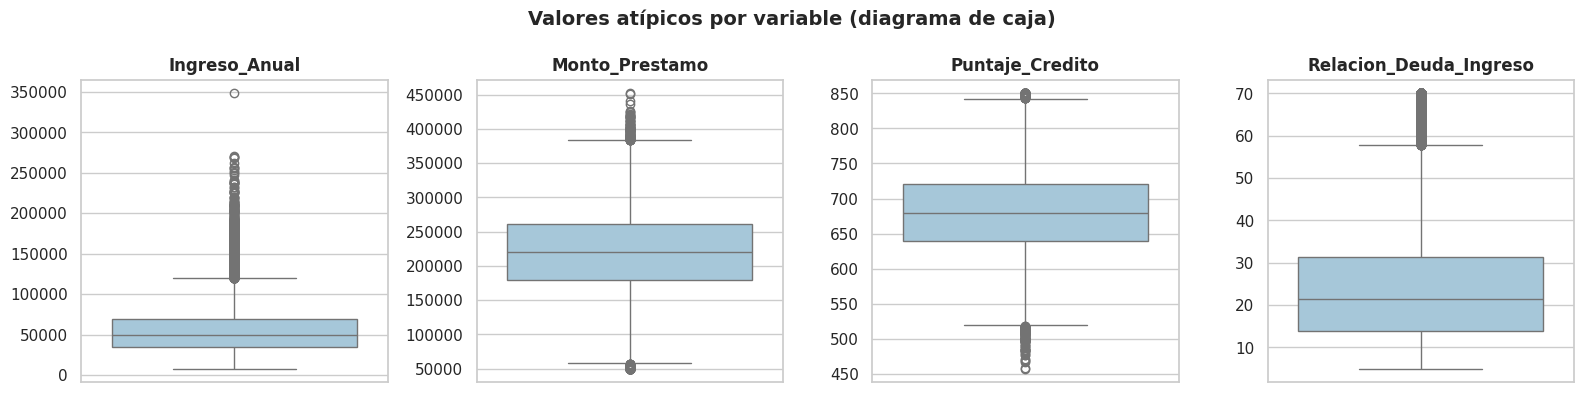

In [10]:
def diagnostico_outliers(serie: pd.Series) -> dict:
    """Cuenta los valores atípicos de una serie con la regla del rango intercuartílico (IQR).

    Un valor es atípico si está bajo Q1 - 1,5*IQR o sobre Q3 + 1,5*IQR.
    Es un diagnóstico solo descriptivo: no transforma ni elimina datos.
    """
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_atipicos = int(((serie < limite_inferior) | (serie > limite_superior)).sum())
    return {
        "limite_inferior": round(limite_inferior, 2),
        "limite_superior": round(limite_superior, 2),
        "n_atipicos": n_atipicos,
        "% atípicos": round(n_atipicos / len(serie) * 100, 2),
        "asimetria": round(serie.skew(), 2),
    }


variables_numericas = ["Ingreso_Anual", "Monto_Prestamo", "Puntaje_Credito", "Relacion_Deuda_Ingreso"]
tabla_outliers = pd.DataFrame({col: diagnostico_outliers(data[col]) for col in variables_numericas}).T
print(tabla_outliers)

fig, ejes = plt.subplots(1, 4, figsize=(16, 4))
for eje, col in zip(ejes, variables_numericas):
    sns.boxplot(data=data, y=col, ax=eje, color="#9ecae1")
    eje.set_title(col, fontsize=12, fontweight="bold")
    eje.set_ylabel("")
fig.suptitle("Valores atípicos por variable (diagrama de caja)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación (regla IQR).** Hay valores atípicos en las cuatro variables, sobre todo en `Ingreso_Anual` (976 casos, 3,90 %) y `Relacion_Deuda_Ingreso` (663 casos, 2,65 %), las dos con asimetría positiva (1,70 y 0,99). En `Monto_Prestamo` (157 casos) y `Puntaje_Credito` (167 casos) son pocos y la distribución es simétrica. En el ingreso el límite inferior es negativo, por lo que todos los atípicos son ingresos muy altos.

**Decisión: se conservan.** Son valores plausibles (ingresos altos, deudas altas) y los clientes con DTI elevado son justamente los que interesan para medir riesgo; eliminarlos quitaría información real de la cartera. Además, los árboles dividen según el orden de los valores, por lo que los atípicos no distorsionan los umbrales como ocurriría en un modelo lineal.

        clientes      %
Cumple     23211  92.84
Impago      1789   7.16

Accuracy de un 'modelo' que siempre predice Cumple: 0.9284
Impagos que ese 'modelo' detecta: 0 de 1789
Razón Cumple : Impago = 13.0 : 1


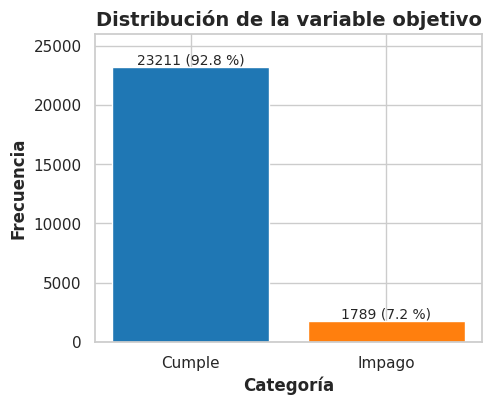

In [11]:
conteo = data["Riesgo_Impago"].value_counts().sort_index()
porcentaje = data["Riesgo_Impago"].value_counts(normalize=True).sort_index() * 100
print(pd.DataFrame({"clientes": conteo.values, "%": porcentaje.round(2).values}, index=NOMBRES_CLASES))

accuracy_siempre_cumple = (data["Riesgo_Impago"] == 0).mean()
print(f"\nAccuracy de un 'modelo' que siempre predice Cumple: {accuracy_siempre_cumple:.4f}")
print(f"Impagos que ese 'modelo' detecta: 0 de {int(conteo[1])}")
print(f"Razón Cumple : Impago = {conteo[0] / conteo[1]:.1f} : 1")

plt.figure(figsize=(5, 4))
plt.bar(NOMBRES_CLASES, conteo.values, color=["#1f77b4", "#ff7f0e"])
for i, valor in enumerate(conteo.values):
    plt.text(i, valor, f"{valor} ({porcentaje.values[i]:.1f} %)", ha="center", va="bottom", fontsize=10)
plt.title("Distribución de la variable objetivo", fontsize=14, fontweight="bold")
plt.xlabel("Categoría", fontsize=12, fontweight="bold")
plt.ylabel("Frecuencia", fontsize=12, fontweight="bold")
plt.ylim(0, conteo.max() * 1.12)
plt.show()

**Interpretación para el negocio.** El objetivo está **fuertemente desbalanceado**: 23.211 clientes cumplen (92,84 %) y solo 1.789 incurren en impago (7,16 %), una razón de 13,0 a 1. Un "modelo" que aprobara a todos acertaría el 92,84 % de las veces y no detectaría ninguno de los 1.789 impagos. Por eso el **accuracy engaña** en este problema, y de aquí salen tres decisiones: dividir con `stratify`, usar `class_weight` en la búsqueda de hiperparámetros y elegir métricas centradas en la clase Impago.

In [12]:
# Perfil promedio de cada grupo (descriptivo; asociaciones, no causas)
data.groupby("Riesgo_Impago")[variables_numericas].mean().round(2)

,Ingreso_Anual,Monto_Prestamo,Puntaje_Credito,Relacion_Deuda_Ingreso
Riesgo_Impago,,,,
0,56757.46,218140.82,682.36,22.86
1,43719.24,246397.83,649.85,39.18


**Lectura descriptiva.** En promedio, los clientes en impago tienen un DTI mucho mayor (39,18 % frente a 22,86 %), un puntaje de crédito menor (649,85 frente a 682,36), un ingreso menor (\$43.719 frente a \$56.757) y piden un monto mayor (\$246.398 frente a \$218.141). Son asociaciones, no causas, pero anticipan que el DTI será una variable importante.

# Fase 2: Limpieza y tratamiento de datos (Pipeline)

In [13]:
X = data.drop(columns="Riesgo_Impago")
y = data["Riesgo_Impago"]
columnas_numericas = list(X.columns)

# Preprocesador: solo imputación defensiva por mediana (no hay nulos) y sin escalado, porque el árbol no lo necesita.
# Se ajusta únicamente con los datos de entrenamiento cuando se ajusta el Pipeline completo.
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", Pipeline(steps=[("imputador", SimpleImputer(strategy="median"))]), columnas_numericas),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

print("Variables predictoras:", columnas_numericas)
preprocesador

Variables predictoras: ['Ingreso_Anual', 'Monto_Prestamo', 'Puntaje_Credito', 'Relacion_Deuda_Ingreso']


ColumnTransformer(transformers=[('numericas',
                                 Pipeline(steps=[('imputador',
                                                  SimpleImputer(strategy='median'))]),
                                 ['Ingreso_Anual', 'Monto_Prestamo',
                                  'Puntaje_Credito',
                                  'Relacion_Deuda_Ingreso'])],
                  verbose_feature_names_out=False)

**Decisiones del pipeline.**

- **Imputación por mediana (defensiva):** los datos no tienen nulos, por lo que no se imputa nada hoy; se deja el paso para que el flujo funcione si llegan solicitudes nuevas con datos faltantes. La mediana es robusta a los atípicos que se conservaron.
- **Sin escalado:** los árboles de decisión eligen umbrales según el orden de los valores, así que escalar no cambia el árbol. Al no escalar, los umbrales quedan en unidades originales (dólares, puntos, porcentaje), interpretables para el banco. Si se quisiera seguir la convención de escalado del curso (RobustScaler para variables con atípicos y StandardScaler para el resto), las predicciones del árbol serían las mismas, porque sus divisiones dependen solo del orden de los valores.
- **Sin codificación:** todas las variables son numéricas.
- **Sin fuga de datos:** el preprocesador va dentro de un `Pipeline` que se ajusta solo con los datos de entrenamiento. En la búsqueda de hiperparámetros se entrega el pipeline completo, de modo que el preprocesamiento se reajusta en cada pliegue de validación cruzada.

# Fase 3: Construcción del modelo

## División en entrenamiento y prueba

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"Entrenamiento: {len(X_train)} | Prueba: {len(X_test)}")
print(f"% impago -> total: {y.mean()*100:.2f} | train: {y_train.mean()*100:.2f} | test: {y_test.mean()*100:.2f}")
print(f"Impagos -> train: {int(y_train.sum())} | test: {int(y_test.sum())}")

Entrenamiento: 15000 | Prueba: 10000
% impago -> total: 7.16 | train: 7.15 | test: 7.16
Impagos -> train: 1073 | test: 716


La división es **estratificada** (`stratify=y`) y usa `random_state = 29`: quedan 15.000 filas para entrenamiento y 10.000 para prueba, con la misma proporción de impagos en ambos conjuntos (7,15 % y 7,16 %; 1.073 y 716 impagos). El conjunto de prueba solo se usa para la evaluación final.

## Modelo de línea base

Árbol por defecto, sin límites de profundidad (suele memorizar).

In [15]:
# Línea base: árbol por defecto (sin hiperparámetros)
baseline_tree = Pipeline(steps=[
    ("preprocesamiento", preprocesador),
    ("arbol", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
baseline_tree.fit(X_train, y_train)

y_pred_base = baseline_tree.predict(X_test)
y_proba_base = baseline_tree.predict_proba(X_test)[:, 1]
print("Línea base entrenada.")

Línea base entrenada.


In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_pred_base_train = baseline_tree.predict(X_train)
arbol_base = baseline_tree.named_steps["arbol"]

diagnostico_base = pd.Series({
    "Recall impago - entrenamiento": recall_score(y_train, y_pred_base_train),
    "Recall impago - prueba": recall_score(y_test, y_pred_base),
    "F1 impago - entrenamiento": f1_score(y_train, y_pred_base_train),
    "F1 impago - validación cruzada (media)": cross_val_score(
        baseline_tree, X_train, y_train, cv=cv, scoring="f1").mean(),
    "F1 impago - prueba": f1_score(y_test, y_pred_base),
    "Profundidad del árbol": arbol_base.get_depth(),
    "Número de hojas": arbol_base.get_n_leaves(),
}, name="línea base")
print(diagnostico_base.round(4))

Recall impago - entrenamiento                1.0000
Recall impago - prueba                       0.3212
F1 impago - entrenamiento                    1.0000
F1 impago - validación cruzada (media)       0.2558
F1 impago - prueba                           0.2953
Profundidad del árbol                       31.0000
Número de hojas                           1208.0000
Name: línea base, dtype: float64


### Diagnóstico de la línea base: ¿generaliza o memoriza?

1. **¿Generaliza o memoriza?** **Memoriza.** El árbol por defecto crece sin límite hasta una profundidad de 31 y 1.208 hojas.
2. **¿Cómo se sabe?** Por la brecha entre entrenamiento y prueba: en entrenamiento el recall y el F1 de la clase Impago son 1,0000 (acierta todo lo que vio), pero en prueba bajan a 0,3212 y 0,2953, y la validación cruzada da un F1 medio de 0,2558.
3. **¿Qué significa que un modelo generalice?** Que mantiene un desempeño similar con datos que no vio durante el entrenamiento, en vez de repetir lo memorizado.
4. **¿Qué criterio se usó para pasar un modelo a producción?** El desempeño debe ser parecido en entrenamiento, validación cruzada y prueba. La línea base **no cumple** ese criterio y **no puede pasar a producción**: ante clientes nuevos repetiría patrones memorizados.

## Modelo optimizado con `GridSearchCV`

Se prueban cinco hiperparámetros del árbol, dentro del pipeline completo:

- `criterion` (`gini`, `entropy`): criterio de pureza para dividir nodos.
- `max_depth` (3, 4, 5, 6, 8): limita la profundidad y es el principal freno a la memorización.
- `min_samples_split` (5, 10, 20): mínimo de clientes para poder dividir un nodo.
- `min_samples_leaf` (2, 5, 10): mínimo de clientes en una hoja.
- `class_weight` (`None`, `balanced`): da más peso a la clase Impago, clave con solo 7,16 % de impagos.

La validación es estratificada de 5 pliegues y la métrica de selección es el **F1 de la clase Impago**, que resume recall y precisión. Se descarta `accuracy` porque "aprobar a todos" ya logra 0,9284.

In [17]:
param_grid = {
    "arbol__criterion": ["gini", "entropy"],        # criterio de pureza
    "arbol__max_depth": [3, 4, 5, 6, 8],            # controla la profundidad (evita memorizar)
    "arbol__min_samples_split": [5, 10, 20],        # mínimo de muestras para dividir un nodo
    "arbol__min_samples_leaf": [2, 5, 10],          # mínimo de muestras en una hoja
    "arbol__class_weight": [None, "balanced"],      # pesos de clase: clave con desbalance
}

grid_search = GridSearchCV(
    estimator=Pipeline(steps=[
        ("preprocesamiento", preprocesador),
        ("arbol", DecisionTreeClassifier(random_state=RANDOM_STATE)),
    ]),
    param_grid=param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1",
    n_jobs=-1,
)
grid_search.fit(X_train, y_train)
best_tree = grid_search.best_estimator_

y_pred_opt = best_tree.predict(X_test)
y_proba_opt = best_tree.predict_proba(X_test)[:, 1]

n_combinaciones = len(grid_search.cv_results_["params"])
print(f"Combinaciones evaluadas: {n_combinaciones} | ajustes totales (x5 pliegues): {n_combinaciones * 5}")
print("Mejores hiperparámetros:", grid_search.best_params_)
print(f"Mejor F1 en validación cruzada: {grid_search.best_score_:.4f}")

Combinaciones evaluadas: 180 | ajustes totales (x5 pliegues): 900
Mejores hiperparámetros: {'arbol__class_weight': 'balanced', 'arbol__criterion': 'gini', 'arbol__max_depth': 6, 'arbol__min_samples_leaf': 2, 'arbol__min_samples_split': 5}
Mejor F1 en validación cruzada: 0.3113


Se evaluaron **180 combinaciones** (900 ajustes en total con los 5 pliegues). La mejor combinación usa `class_weight="balanced"`, criterio `gini`, `max_depth=6`, `min_samples_split=5` y `min_samples_leaf=2`, con un F1 de validación cruzada de 0,3113. Dos de los valores elegidos (`min_samples_split=5` y `min_samples_leaf=2`) están en el borde inferior de la grilla, por lo que una búsqueda posterior podría explorar valores aún menores.

Se eligió F1 de la clase Impago como criterio de selección porque resume recall y precisión sin mirar el conjunto de prueba. Un criterio de selección ligado directamente al costo (por ejemplo, un scorer de costo evaluado solo dentro de la validación cruzada) podría reducir aún más el costo total; queda como mejora futura.

In [18]:
arbol_opt = best_tree.named_steps["arbol"]
y_pred_opt_train = best_tree.predict(X_train)

diagnostico_opt = pd.Series({
    "Recall impago - entrenamiento": recall_score(y_train, y_pred_opt_train),
    "Recall impago - prueba": recall_score(y_test, y_pred_opt),
    "F1 impago - entrenamiento": f1_score(y_train, y_pred_opt_train),
    "F1 impago - validación cruzada (media)": grid_search.best_score_,
    "F1 impago - prueba": f1_score(y_test, y_pred_opt),
    "Profundidad del árbol": arbol_opt.get_depth(),
    "Número de hojas": arbol_opt.get_n_leaves(),
}, name="optimizado")
print(pd.concat([diagnostico_base, diagnostico_opt], axis=1).round(4))

                                        línea base  optimizado
Recall impago - entrenamiento               1.0000      0.8397
Recall impago - prueba                      0.3212      0.7696
F1 impago - entrenamiento                   1.0000      0.3107
F1 impago - validación cruzada (media)      0.2558      0.3113
F1 impago - prueba                          0.2953      0.2856
Profundidad del árbol                      31.0000      6.0000
Número de hojas                          1208.0000     56.0000


**¿El modelo optimizado generaliza?** Sí, en el sentido de que ya no memoriza: su profundidad baja a 6 y a 56 hojas (la línea base tenía 31 y 1.208), y su F1 es parecido en entrenamiento (0,3107), validación cruzada (0,3113) y prueba (0,2856). El recall pasa de 0,8397 en entrenamiento a 0,7696 en prueba, una brecha moderada. Que el F1 sea bajo en los tres conjuntos indica que las cuatro variables disponibles separan de forma limitada a los clientes en impago; no es un problema de memorización.

In [19]:
proba_opt = best_tree.predict_proba(X_test)
print("Forma de predict_proba:", proba_opt.shape, "| filas de X_test:", len(X_test))
print("¿Cada fila suma 1?:", bool(np.allclose(proba_opt.sum(axis=1), 1)))
print("¿y_pred_opt = clase de mayor probabilidad?:",
      bool(np.array_equal(best_tree.classes_[proba_opt.argmax(axis=1)], y_pred_opt)))
print("Probabilidades [Cumple, Impago] de las últimas 5 filas:")
print(proba_opt[-5:].round(3))
print("Predicciones de esas 5 filas:", y_pred_opt[-5:])

Forma de predict_proba: (10000, 2) | filas de X_test: 10000
¿Cada fila suma 1?: True
¿y_pred_opt = clase de mayor probabilidad?: True
Probabilidades [Cumple, Impago] de las últimas 5 filas:
[[0.922 0.078]
 [0.803 0.197]
 [0.48  0.52 ]
 [0.794 0.206]
 [0.639 0.361]]
Predicciones de esas 5 filas: [0 0 1 0 0]


**Probabilidades y predicciones.**

- `best_tree.predict_proba(X_test)` tiene **10.000 filas**, tantas como observaciones en `X_test`, y dos columnas (Cumple, Impago).
- **Cada fila suma 1**. La observación se asigna a la clase con mayor probabilidad, y así se obtiene `y_pred_opt` (la comprobación lo confirma). Por ejemplo, la tercera fila mostrada tiene 0,52 de probabilidad de impago y fue clasificada como Impago.
- **¿Se puede encontrar el mejor modelo sin `GridSearchCV`?** Sí, **por fuerza bruta**: entrenando y evaluando manualmente cada combinación de hiperparámetros. `GridSearchCV` automatiza ese recorrido y lo valida con validación cruzada.

# Fase 4: Evaluación e interpretación (conjunto de prueba)

## 4.1 Selección y reporte de métricas

**Las DOS métricas elegidas: recall y precisión de la clase Impago.**

- **Recall (sensibilidad):** de todos los clientes que realmente caerán en impago, ¿qué fracción detecta el modelo? Mide el error **más caro**: cada impago no detectado (falso negativo) cuesta \$1.500.000.
- **Precisión:** de todos los clientes que el modelo marca como Impago, ¿qué fracción lo es realmente? Mide el otro error: cada cliente cumplidor rechazado (falso positivo) cuesta \$200.000 en intereses no percibidos.
- **Por qué no `accuracy`:** con 7,16 % de impagos, aprobar a todos ya da 0,9284 sin detectar ningún impago.

Las dos métricas son complementarias: mejorar una suele empeorar la otra, y los costos asimétricos del negocio indican cómo equilibrarlas. Ambas se calculan con la clase Impago como positiva. El resto de las cifras (F1, accuracy) es información adicional.

In [20]:
def resumen_modelo(nombre: str, y_real, y_pred) -> dict:
    """Matriz de confusión, las dos métricas elegidas y el costo financiero de un modelo.

    La clase positiva es Impago (1). Costo total = FN x COSTO_FN + FP x COSTO_FP.
    """
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    return {
        "modelo": nombre, "VN": vn, "FP": fp, "FN": fn, "VP": vp,
        "recall_impago": recall_score(y_real, y_pred, pos_label=1),
        "precision_impago": precision_score(y_real, y_pred, pos_label=1, zero_division=0),
        "costo_FN": fn * COSTO_FN, "costo_FP": fp * COSTO_FP,
        "costo_total": fn * COSTO_FN + fp * COSTO_FP,
    }


tabla_resumen = pd.DataFrame([
    resumen_modelo("Línea base", y_test, y_pred_base),
    resumen_modelo("Optimizado", y_test, y_pred_opt),
]).set_index("modelo")
print(tabla_resumen[["recall_impago", "precision_impago"]].round(4))

            recall_impago  precision_impago
modelo                                     
Línea base         0.3212            0.2732
Optimizado         0.7696            0.1753


In [21]:
print("--- REPORTE DE CLASIFICACIÓN (LÍNEA BASE) ---")
print(classification_report(y_test, y_pred_base, target_names=NOMBRES_CLASES, zero_division=0))
print("--- REPORTE DE CLASIFICACIÓN (MODELO OPTIMIZADO) ---")
print(classification_report(y_test, y_pred_opt, target_names=NOMBRES_CLASES, zero_division=0))

--- REPORTE DE CLASIFICACIÓN (LÍNEA BASE) ---
              precision    recall  f1-score   support

      Cumple       0.95      0.93      0.94      9284
      Impago       0.27      0.32      0.30       716

    accuracy                           0.89     10000
   macro avg       0.61      0.63      0.62     10000
weighted avg       0.90      0.89      0.89     10000

--- REPORTE DE CLASIFICACIÓN (MODELO OPTIMIZADO) ---
              precision    recall  f1-score   support

      Cumple       0.98      0.72      0.83      9284
      Impago       0.18      0.77      0.29       716

    accuracy                           0.72     10000
   macro avg       0.58      0.75      0.56     10000
weighted avg       0.92      0.72      0.79     10000



**Resultados en el conjunto de prueba (10.000 clientes, 716 impagos reales):**

| Modelo | Recall (Impago) | Precisión (Impago) |
|---|---|---|
| Línea base | 0,3212 | 0,2732 |
| Optimizado | 0,7696 | 0,1753 |

El modelo optimizado detecta **77 de cada 100 impagos** frente a 32 de la línea base, pero a cambio su precisión baja: de cada 100 clientes que marca como Impago, solo unos 18 lo son (27 en la línea base). Aun así, esa precisión es superior al 7,16 % de impago de toda la cartera. El accuracy cae de 0,89 a 0,72, lo que **no** significa que el modelo sea peor: el accuracy premia aprobar a casi todos, que es justo lo que el banco no quiere.

El F1 de la clase Impago es parecido en ambos (0,30 y 0,29): optimizar con F1 no lo mejoró en prueba, pero sí movió el modelo hacia detectar más impagos, que es lo que importa por el costo.

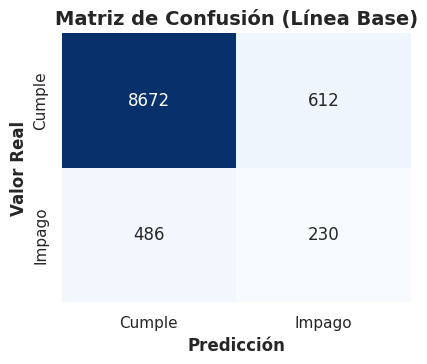

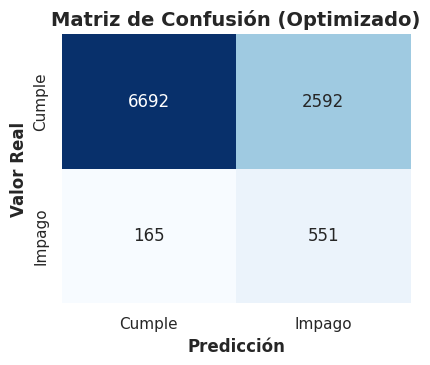

,VN,FP,FN,VP
modelo,,,,
Línea base,8672,612,486,230
Optimizado,6692,2592,165,551


In [22]:
def view_matrix(y_real, y_pred, descripcion: str):
    """Muestra la matriz de confusión como mapa de calor (filas = valor real, columnas = predicción)."""
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(
        confusion_matrix(y_real, y_pred, labels=[0, 1]),
        annot=True, fmt="d", cmap="Blues", cbar=False,
        xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES,
    )
    plt.xlabel("Predicción", fontsize=12, fontweight="bold")
    plt.ylabel("Valor Real", fontsize=12, fontweight="bold")
    plt.title(f"Matriz de Confusión ({descripcion})", fontsize=14, fontweight="bold")
    plt.show()


view_matrix(y_test, y_pred_base, "Línea Base")
view_matrix(y_test, y_pred_opt, "Optimizado")
tabla_resumen[["VN", "FP", "FN", "VP"]]

### 4.2 Interpretación de las matrices de confusión

**Cómo leerlas.** Las filas son el valor real y las columnas la predicción. El **color** indica cuántas personas hay en cada cuadrante: cuanto más intenso el azul, más personas. En ambos modelos el cuadrante más oscuro es el de los verdaderos negativos (clientes que cumplen y fueron aprobados), porque son la gran mayoría.

- **VN (verdadero negativo):** cliente que cumple y se aprueba. Es el resultado deseado.
- **FP (falso positivo):** cliente que cumpliría pero se rechaza. Cuesta **\$200.000** en intereses no percibidos.
- **FN (falso negativo):** cliente que cae en impago pero se aprueba. Cuesta **\$1.500.000** de capital.
- **VP (verdadero positivo):** impago detectado y rechazado: se evita la pérdida.

**Línea base (VN = 8.672, FP = 612, FN = 486, VP = 230).** Detecta solo 230 de los 716 impagos (32,1 %): **486 impagos pasan sin ser detectados** (67,9 %), con un costo de \$729.000.000. Rechaza injustamente a 612 clientes que habrían pagado (6,6 % de los cumplidores), con un costo de \$122.400.000. El **85,6 %** de su costo total proviene de falsos negativos: es un modelo permisivo, que aprueba casi todo y deja pasar la mayor parte del riesgo. Además, por memorizar, no es confiable con clientes nuevos.

**Optimizado (VN = 6.692, FP = 2.592, FN = 165, VP = 551).** Detecta 551 de los 716 impagos (77,0 %) y deja pasar solo 165 (23,0 %), con un costo de \$247.500.000. A cambio rechaza a 2.592 clientes que habrían pagado (27,9 % de los cumplidores), con un costo de \$518.400.000. Ahora el **67,7 %** de su costo proviene de falsos positivos: es un modelo conservador, que protege el capital a costa de renunciar a más negocio viable.

In [23]:
costos = tabla_resumen[["FP", "FN", "costo_FP", "costo_FN", "costo_total"]].copy()
print(costos.map(lambda v: f"{v:,.0f}".replace(",", ".")))

costo_base = tabla_resumen.loc["Línea base", "costo_total"]
costo_opt = tabla_resumen.loc["Optimizado", "costo_total"]
ahorro = costo_base - costo_opt
print(f"\nAhorro del optimizado frente a la línea base: ${ahorro:,.0f}".replace(",", "."))
print(f"Ahorro relativo: {ahorro / costo_base * 100:.1f} %")
print(f"Falsos negativos evitados por el optimizado: {int(tabla_resumen.loc['Línea base', 'FN'] - tabla_resumen.loc['Optimizado', 'FN'])}")
print(f"Falsos positivos adicionales del optimizado: {int(tabla_resumen.loc['Optimizado', 'FP'] - tabla_resumen.loc['Línea base', 'FP'])}")
print(f"Un falso negativo cuesta {COSTO_FN / COSTO_FP:.1f} veces un falso positivo")

tasas = pd.DataFrame({
    "impagos detectados (recall) %": tabla_resumen["VP"] / (tabla_resumen["VP"] + tabla_resumen["FN"]) * 100,
    "impagos no detectados %": tabla_resumen["FN"] / (tabla_resumen["VP"] + tabla_resumen["FN"]) * 100,
    "clientes viables rechazados %": tabla_resumen["FP"] / (tabla_resumen["FP"] + tabla_resumen["VN"]) * 100,
    "% del costo total por falsos negativos": tabla_resumen["costo_FN"] / tabla_resumen["costo_total"] * 100,
    "% del costo total por falsos positivos": tabla_resumen["costo_FP"] / tabla_resumen["costo_total"] * 100,
}).round(1)
print()
print(tasas.T)

# Referencia: costo de aprobar a todos y de rechazar a todos (sin modelo), sobre el conjunto de prueba
n_impagos_test = int(y_test.sum())
n_cumplen_test = int((y_test == 0).sum())
print(f"Costo de aprobar a todos (sin modelo): ${n_impagos_test * COSTO_FN:,.0f}".replace(",", "."))
print(f"Costo de rechazar a todos (sin modelo): ${n_cumplen_test * COSTO_FP:,.0f}".replace(",", "."))

               FP   FN     costo_FP     costo_FN  costo_total
modelo                                                       
Línea base    612  486  122.400.000  729.000.000  851.400.000
Optimizado  2.592  165  518.400.000  247.500.000  765.900.000

Ahorro del optimizado frente a la línea base: $85.500.000
Ahorro relativo: 10.0 %
Falsos negativos evitados por el optimizado: 321
Falsos positivos adicionales del optimizado: 1980
Un falso negativo cuesta 7.5 veces un falso positivo

modelo                                  Línea base  Optimizado
impagos detectados (recall) %                 32.1        77.0
impagos no detectados %                       67.9        23.0
clientes viables rechazados %                  6.6        27.9
% del costo total por falsos negativos        85.6        32.3
% del costo total por falsos positivos        14.4        67.7
Costo de aprobar a todos (sin modelo): $1.074.000.000
Costo de rechazar a todos (sin modelo): $1.856.800.000


**Comparación de costos (conjunto de prueba, 10.000 solicitudes).**

| Modelo | Costo por FN | Costo por FP | Costo total |
|---|---|---|---|
| Línea base | \$729.000.000 | \$122.400.000 | \$851.400.000 |
| Optimizado | \$247.500.000 | \$518.400.000 | \$765.900.000 |

- **El modelo optimizado cuesta menos:** ahorra **\$85.500.000** (10,0 %) frente a la línea base.
- **Cuál error es más caro:** un falso negativo cuesta 7,5 veces un falso positivo. Por eso conviene tolerar varios falsos positivos para evitar un falso negativo, y por eso el optimizado, que cambia 321 falsos negativos menos por 1.980 falsos positivos más, sigue saliendo más barato.
- **Referencia sin modelo:** aprobar a todos costaría \$1.074.000.000 y rechazar a todos \$1.856.800.000. Ambos modelos quedan por debajo de las dos alternativas.

**Qué no resuelve el modelo (limitaciones).**

- Se evalúa con un único conjunto de prueba; la cifra de ahorro tiene incertidumbre que no se midió.
- Los costos del enunciado son fijos por crédito; en la práctica, la pérdida por impago depende del monto del préstamo.
- Las probabilidades de un árbol no están calibradas (ver análisis siguiente).
- El F1 cercano a 0,3 muestra que, con estas cuatro variables, el poder de discriminación es modesto; rechazar a 27,9 % de los clientes viables tiene un costo comercial que el costo de \$200.000 puede no capturar por completo.

In [24]:
# Umbral teórico: marcar como Impago si P(impago) > COSTO_FP / (COSTO_FN + COSTO_FP)
umbral_teorico = COSTO_FP / (COSTO_FN + COSTO_FP)
y_pred_umbral = (y_proba_opt >= umbral_teorico).astype(int)
fila_umbral = resumen_modelo("Optimizado con umbral teórico", y_test, y_pred_umbral)

print(f"Umbral teórico: {umbral_teorico * 100:.1f} % (frente al 50 % que usa predict por defecto)")
tabla_umbral = pd.DataFrame([fila_umbral]).set_index("modelo")
print(tabla_umbral[["VN", "FP", "FN", "VP"]])
print(tabla_umbral[["recall_impago", "precision_impago"]].round(4))
print(f"Costo total con umbral teórico: ${fila_umbral['costo_total']:,.0f}".replace(",", "."))
print(f"Costo total del optimizado con umbral 0,5: ${costo_opt:,.0f}".replace(",", "."))

Umbral teórico: 11.8 % (frente al 50 % que usa predict por defecto)
                                 VN    FP  FN   VP
modelo                                            
Optimizado con umbral teórico  4472  4812  65  651
                               recall_impago  precision_impago
modelo                                                        
Optimizado con umbral teórico         0.9092            0.1192
Costo total con umbral teórico: $1.059.900.000
Costo total del optimizado con umbral 0.5: $765.900.000


**Análisis opcional: ¿y el umbral de decisión?** Con estos costos, lo racional sería marcar como Impago a quien tenga una probabilidad mayor a 200.000 / (1.500.000 + 200.000) = **11,8 %**, mucho menor que el 50 % que usa `predict` por defecto.

Al aplicarlo sobre las probabilidades del modelo optimizado, el recall sube a 0,9092 (solo 65 impagos sin detectar), pero la precisión cae a 0,1192 y se rechaza a 4.812 clientes viables: el **costo total sube a \$1.059.900.000**, peor que los \$765.900.000 con umbral 0,5. La razón es que esa regla supone probabilidades **calibradas**, y aquí no lo están: `class_weight="balanced"` infla la probabilidad de impago, y las hojas con pocos clientes dan estimaciones poco fiables. Por lo tanto, **no se adopta** este umbral. Para usarlo habría que calibrar las probabilidades o elegir el umbral con validación cruzada sobre los datos de entrenamiento (nunca sobre el conjunto de prueba).

                 Variable  Importancia
3  Relacion_Deuda_Ingreso       0.5547
2         Puntaje_Credito       0.1720
0           Ingreso_Anual       0.1596
1          Monto_Prestamo       0.1137
Suma de importancias: 1.0


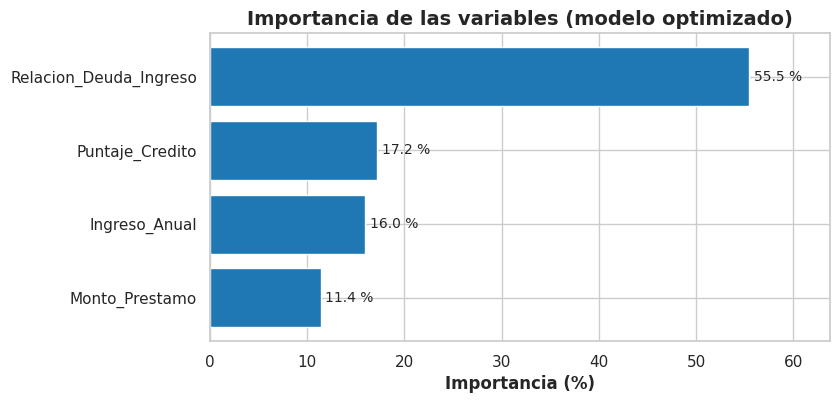

In [25]:
nombres_variables = list(best_tree.named_steps["preprocesamiento"].get_feature_names_out())
importancias = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": best_tree.named_steps["arbol"].feature_importances_,
}).sort_values("Importancia", ascending=False)
print(importancias.round(4))
print("Suma de importancias:", round(importancias["Importancia"].sum(), 6))

plt.figure(figsize=(8, 4))
orden = importancias.sort_values("Importancia")
barras = plt.barh(orden["Variable"], orden["Importancia"] * 100, color="#1f77b4")
for barra in barras:
    plt.text(barra.get_width() + 0.5, barra.get_y() + barra.get_height() / 2,
             f"{barra.get_width():.1f} %", va="center", fontsize=10)
plt.title("Importancia de las variables (modelo optimizado)", fontsize=14, fontweight="bold")
plt.xlabel("Importancia (%)", fontsize=12, fontweight="bold")
plt.xlim(0, orden["Importancia"].max() * 100 * 1.15)
plt.show()

**Importancia de variables (modelo optimizado).** El DTI domina con 55,47 %, seguido por el puntaje de crédito (17,20 %), el ingreso anual (15,96 %) y el monto del préstamo (11,37 %); suman 1, como corresponde. Esto coincide con el perfil descriptivo: los impagos tienen un DTI promedio mucho mayor. Son **asociaciones, no causas**, y la importancia de un árbol puede sobrestimar variables con muchos valores distintos.

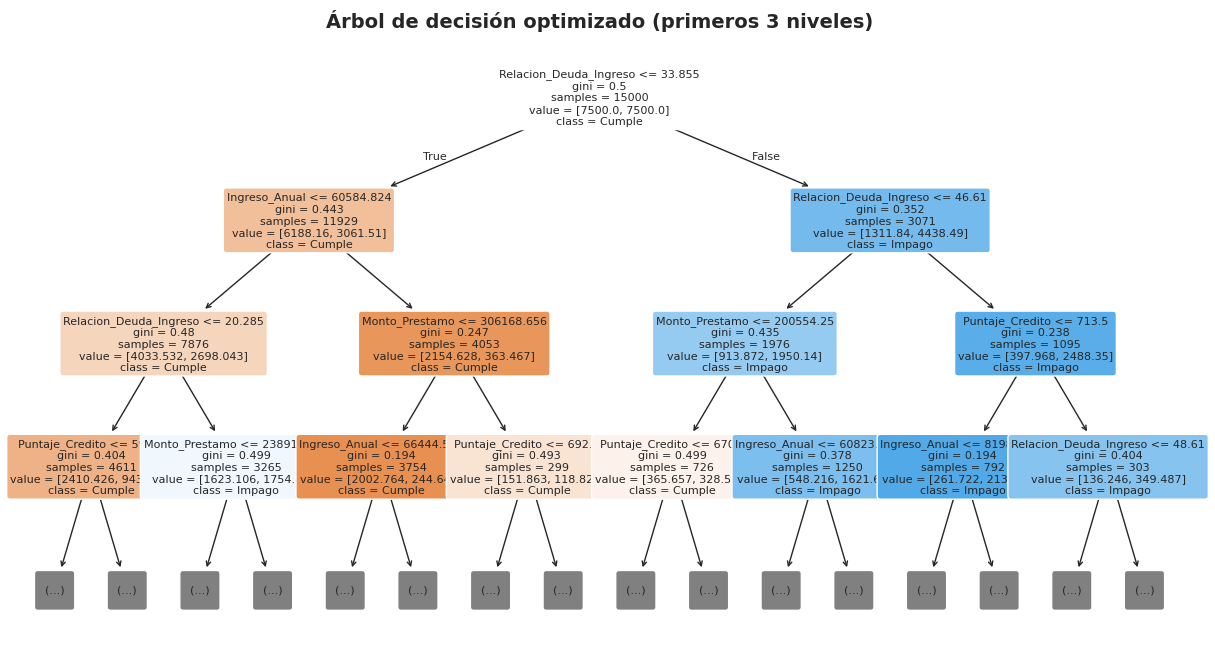

In [26]:
plt.figure(figsize=(15, 8))
plot_tree(
    best_tree.named_steps["arbol"],
    feature_names=nombres_variables,
    class_names=NOMBRES_CLASES,
    filled=True, rounded=True, max_depth=3, fontsize=8,
)
plt.title("Árbol de decisión optimizado (primeros 3 niveles)", fontsize=14, fontweight="bold")
plt.show()

# Cierre

## Resumen de cifras para la presentación

In [27]:
vn_b, fp_b, fn_b, vp_b = (int(tabla_resumen.loc["Línea base", c]) for c in ["VN", "FP", "FN", "VP"])
vn_o, fp_o, fn_o, vp_o = (int(tabla_resumen.loc["Optimizado", c]) for c in ["VN", "FP", "FN", "VP"])
fmt = lambda v: f"${v:,.0f}".replace(",", ".")

print("=== RESUMEN DE CIFRAS PARA LA PRESENTACIÓN ===")
print(f"Filas totales: {len(data)} | Entrenamiento: {len(X_train)} | Prueba: {len(X_test)}")
print(f"Impago en el total: {y.mean()*100:.2f} % ({int(y.sum())} clientes) | Accuracy 'siempre Cumple': {accuracy_siempre_cumple:.4f}")
print(f"Nulos: {int(data.isna().sum().sum())} | Duplicados: {int(data.duplicated().sum())} | Inconsistencias lógicas: {sum(reglas.values())}")
print(f"Atípicos Ingreso_Anual: {tabla_outliers.loc['Ingreso_Anual', 'n_atipicos']:.0f} | Relacion_Deuda_Ingreso: {tabla_outliers.loc['Relacion_Deuda_Ingreso', 'n_atipicos']:.0f}")
print(f"Hiperparámetros óptimos: {grid_search.best_params_}")
print()
for nombre, fila in tabla_resumen.iterrows():
    print(f"{nombre}: recall = {fila['recall_impago']:.4f} | precisión = {fila['precision_impago']:.4f} | "
          f"VN = {int(fila['VN'])} FP = {int(fila['FP'])} FN = {int(fila['FN'])} VP = {int(fila['VP'])} | "
          f"costo FN = {fmt(fila['costo_FN'])} | costo FP = {fmt(fila['costo_FP'])} | costo total = {fmt(fila['costo_total'])}")
print(f"Ahorro del optimizado frente a la línea base: {fmt(ahorro)} ({ahorro / costo_base * 100:.1f} %)")

=== RESUMEN DE CIFRAS PARA LA PRESENTACIÓN ===
Filas totales: 25000 | Entrenamiento: 15000 | Prueba: 10000
Impago en el total: 7.16 % (1789 clientes) | Accuracy 'siempre Cumple': 0.9284
Nulos: 0 | Duplicados: 0 | Inconsistencias lógicas: 0
Atípicos Ingreso_Anual: 976 | Relacion_Deuda_Ingreso: 663
Hiperparámetros óptimos: {'arbol__class_weight': 'balanced', 'arbol__criterion': 'gini', 'arbol__max_depth': 6, 'arbol__min_samples_leaf': 2, 'arbol__min_samples_split': 5}

Línea base: recall = 0.3212 | precisión = 0.2732 | VN = 8672 FP = 612 FN = 486 VP = 230 | costo FN = $729.000.000 | costo FP = $122.400.000 | costo total = $851.400.000
Optimizado: recall = 0.7696 | precisión = 0.1753 | VN = 6692 FP = 2592 FN = 165 VP = 551 | costo FN = $247.500.000 | costo FP = $518.400.000 | costo total = $765.900.000
Ahorro del optimizado frente a la línea base: $85.500.000 (10.0 %)


## Conclusiones

1. **Calidad de datos:** el conjunto está completo (sin nulos, duplicados ni inconsistencias lógicas); solo requirió eliminar el índice `Unnamed: 0`. Los atípicos de ingreso y DTI se conservaron y varias variables están acotadas en sus extremos.
2. **Desbalance:** solo 7,16 % de los clientes cae en impago, por lo que el accuracy (0,9284 de un modelo que aprueba a todos) no sirve para evaluar.
3. **Modelos:** el árbol por defecto memoriza (F1 de 1,0000 en entrenamiento contra 0,2953 en prueba) y no puede pasar a producción. El árbol optimizado (profundidad 6, `class_weight="balanced"`) generaliza y reduce el costo total de \$851.400.000 a \$765.900.000 (10,0 %).
4. **Compromiso de negocio:** el optimizado detecta 77,0 % de los impagos (frente a 32,1 %) a cambio de rechazar a 27,9 % de los clientes viables (frente a 6,6 %). Como un falso negativo cuesta 7,5 veces un falso positivo, ese intercambio resulta conveniente.
5. **Uso recomendado:** el modelo sirve como herramienta de apoyo para priorizar revisiones, no para decidir solo; los clientes que marca podrían pasar por una revisión humana en lugar de un rechazo automático.

## Limitaciones y próximos pasos

- Calibrar las probabilidades y elegir el umbral con validación cruzada.
- Incorporar el monto del préstamo en el costo de cada error.
- Probar modelos más potentes (por ejemplo, ensambles de árboles) y más variables.
- Validar con datos de otro período antes de usarlo en producción.